## Exploratory Data Analysis - Initial Findings

The Mall Customers dataset contains 200 customer records and five attributes: CustomerID, Genre, Age, Annual Income, and Spending Score.

### Data Quality
- No missing values were identified.
- No completely duplicated rows were detected.
- Four columns are numerical and one is categorical.

### Age Distribution
Customer ages range from approximately 18 to 70 years. The distribution appears moderately right-skewed, with a higher concentration of customers around their late twenties and early thirties.

### Annual Income Distribution
Annual income ranges from $15,000 to $137,000. The distribution is positively skewed, with the highest concentration of customers earning approximately $51,000-63,000.

### Spending Score Distribution
Spending scores are most concentrated around 40-60, although substantial variation exists across the full scoring range.

### Income vs. Spending Score
The scatter plot suggests several visually distinguishable customer groups. Customers with similar incomes can have different spending scores, indicating that income alone does not fully describe spending behavior.

### Conclusion
Annual Income and Spending Score are reasonable initial features for customer segmentation. K-Means clustering will be explored to identify groups of customers with similar characteristics. The number and quality of clusters will be evaluated rather than assumed from the visualization alone.

In [56]:
import pandas as pd

In [57]:
df = pd.read_csv('../data/Mall_Customers.csv')
display(df.head())
print("Rows and Columns:", df.shape)

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Rows and Columns: (200, 5)


In [58]:
df.info()
print("\nMissing Values per Column:")
print(df.isnull().sum())
print("\nNumber of Duplicated Rows:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Genre                   200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB

Missing Values per Column:
CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Number of Duplicated Rows: 0


In [59]:
display(df.describe())

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


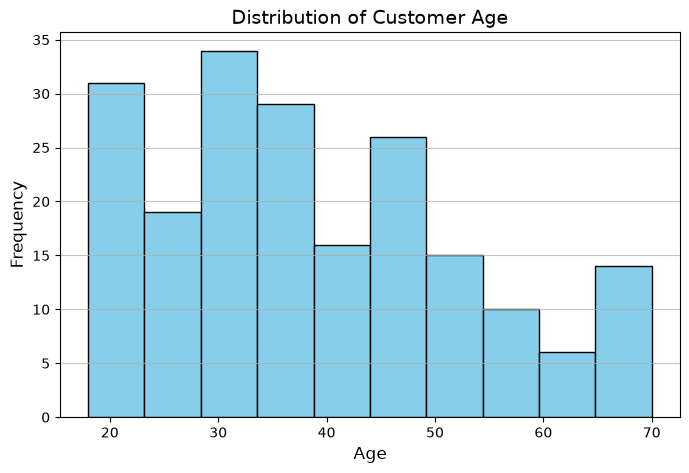

In [60]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.hist(df['Age'], bins=10, color='skyblue', edgecolor='black')
plt.title('Distribution of Customer Age', fontsize=14)
plt.xlabel('Age', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(axis='y', alpha=0.75)
plt.show()

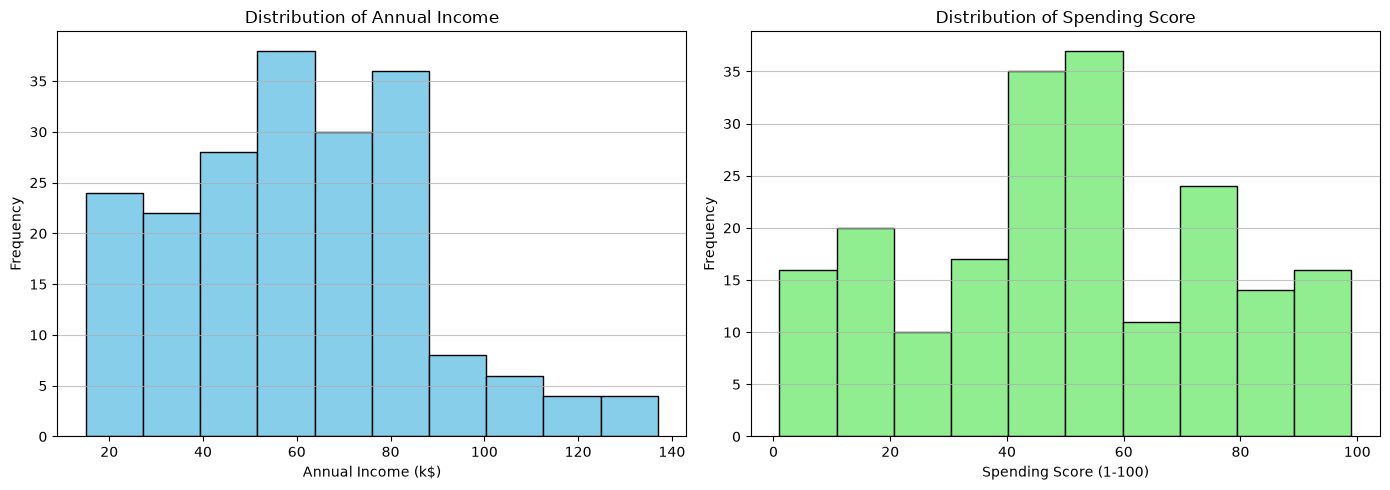

In [61]:
import matplotlib.pyplot as plt

# Create a figure with two subplots side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Histogram for Annual Income
axes[0].hist(df['Annual Income (k$)'], bins=10, color='skyblue', edgecolor='black')
axes[0].set_title('Distribution of Annual Income', fontsize=12)
axes[0].set_xlabel('Annual Income (k$)', fontsize=10)
axes[0].set_ylabel('Frequency', fontsize=10)
axes[0].grid(axis='y', alpha=0.75)

# 2. Histogram for Spending Score
axes[1].hist(df['Spending Score (1-100)'], bins=10, color='lightgreen', edgecolor='black')
axes[1].set_title('Distribution of Spending Score', fontsize=12)
axes[1].set_xlabel('Spending Score (1-100)', fontsize=10)
axes[1].set_ylabel('Frequency', fontsize=10)
axes[1].grid(axis='y', alpha=0.75)

plt.tight_layout()
plt.show()

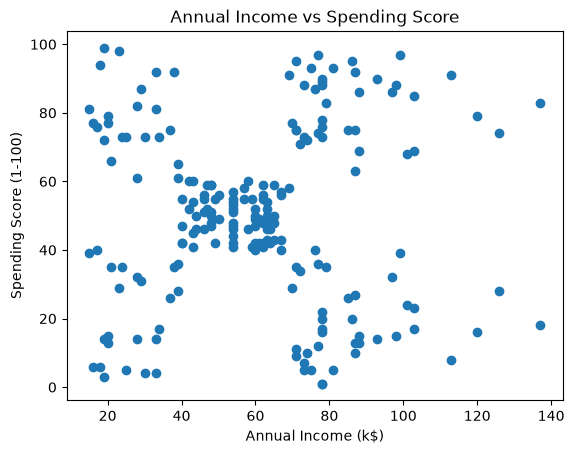

In [62]:
import matplotlib.pyplot as plt

# 1, 2, & 3. Create scatter plot
plt.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'])

# 4. Add title and axis labels
plt.title('Annual Income vs Spending Score')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')

# 5. Display the plot
plt.show()

In [63]:
# 1. Create X with the two selected features
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

# 2. Print the shape of X
print("Shape of X:", X.shape)

# 3. Display the first five rows
display(X.head())

Shape of X: (200, 2)


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [64]:
from sklearn.preprocessing import StandardScaler

# 2. Create a scaler object named scaler
scaler = StandardScaler()

# 3. Apply fit_transform() to X and store the result in X_scaled
X_scaled = scaler.fit_transform(X)

# 4. Print the first five scaled observations
print("First 5 scaled observations:")
print(X_scaled[:5])

# 5. Print the shape of X_scaled
print("\nShape of X_scaled:", X_scaled.shape)

First 5 scaled observations:
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]

Shape of X_scaled: (200, 2)


In [65]:
import numpy as np

print("Means:", np.mean(X_scaled, axis=0))
print("Standard deviations:", np.std(X_scaled, axis=0))

Means: [-2.13162821e-16 -1.46549439e-16]
Standard deviations: [1. 1.]


In [66]:
# 1. Print min and max for each column in X
print("--- Original X ---")
print("Min values:\n", X.min())
print("Max values:\n", X.max())

# 2. Print min and max for each column in X_scaled
print("\n--- Scaled X_scaled ---")
print("Min values:\n", X_scaled.min(axis=0))
print("Max values:\n", X_scaled.max(axis=0))

--- Original X ---
Min values:
 Annual Income (k$)        15
Spending Score (1-100)     1
dtype: int64
Max values:
 Annual Income (k$)        137
Spending Score (1-100)     99
dtype: int64

--- Scaled X_scaled ---
Min values:
 [-1.73899919 -1.91002079]
Max values:
 [2.91767117 1.89449216]


In [67]:
from sklearn.cluster import KMeans

# 2. Create a KMeans model with 5 clusters
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

# 3. Fit the model on X_scaled
kmeans.fit(X_scaled)

# 4. Print the model's cluster labels
print("Cluster labels:\n", kmeans.labels_)

# 5. Print the number of labels
print("\nTotal number of labels:", len(kmeans.labels_))

Cluster labels:
 [4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4
 2 4 2 4 2 4 0 4 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 1 3 1 0 1 3 1 3 1 0 1 3 1 3 1 3 1 3 1 0 1 3 1 3 1
 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3
 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1]

Total number of labels: 200


In [68]:
import numpy as np

# 1. Print the first 10 cluster labels
print("First 10 cluster labels:", kmeans.labels_[:10])

# 2. Print the unique cluster labels using np.unique()
print("Unique cluster labels:", np.unique(kmeans.labels_))

# 3. Print the shape of kmeans.cluster_centers_
print("Shape of cluster centers:", kmeans.cluster_centers_.shape)

# 4. Print the centroid coordinates
print("Centroid coordinates (scaled):\n", kmeans.cluster_centers_)

First 10 cluster labels: [4 2 4 2 4 2 4 2 4 2]
Unique cluster labels: [0 1 2 3 4]
Shape of cluster centers: (5, 2)
Centroid coordinates (scaled):
 [[-0.20091257 -0.02645617]
 [ 0.99158305  1.23950275]
 [-1.32954532  1.13217788]
 [ 1.05500302 -1.28443907]
 [-1.30751869 -1.13696536]]


In [69]:
print("Number of customers:", X_scaled.shape[0])
print("Number of labels:", len(kmeans.labels_))
print("Unique cluster IDs:", np.unique(kmeans.labels_))

Number of customers: 200
Number of labels: 200
Unique cluster IDs: [0 1 2 3 4]


In [70]:
import numpy as np

# 1. & 2. Get unique cluster labels and count occurrences
unique_labels, counts = np.unique(kmeans.labels_, return_counts=True)

# 3. Print each cluster ID alongside its customer count
print("Cluster ID | Customer Count")
print("-" * 30)
for label, count in zip(unique_labels, counts):
    print(f"Cluster {label:<9} | {count}")

# 4. Verify that the total number of customers across all clusters is 200
total_customers = counts.sum()
print("-" * 30)
print(f"Total Customers: {total_customers}")

# Optional assertion check
assert total_customers == 200, "Warning: Total customer count does not equal 200!"
print("Verification successful: All 200 customers accounted for!")

Cluster ID | Customer Count
------------------------------
Cluster 0         | 81
Cluster 1         | 39
Cluster 2         | 22
Cluster 3         | 35
Cluster 4         | 23
------------------------------
Total Customers: 200
Verification successful: All 200 customers accounted for!


In [71]:
print("First 10 labels:", kmeans.labels_[:10])
print("Unique labels:", np.unique(kmeans.labels_))
print("Label shape:", kmeans.labels_.shape)

print("Centroid shape:", kmeans.cluster_centers_.shape)
print("Centroids:\n", kmeans.cluster_centers_)

First 10 labels: [4 2 4 2 4 2 4 2 4 2]
Unique labels: [0 1 2 3 4]
Label shape: (200,)
Centroid shape: (5, 2)
Centroids:
 [[-0.20091257 -0.02645617]
 [ 0.99158305  1.23950275]
 [-1.32954532  1.13217788]
 [ 1.05500302 -1.28443907]
 [-1.30751869 -1.13696536]]


In [72]:
# 1, 2, & 3. Print the number of clusters and the rounded inertia
print(f"Number of Clusters: {kmeans.n_clusters}")
print(f"Inertia: {round(kmeans.inertia_, 2)}")

Number of Clusters: 5
Inertia: 65.57


In [73]:
# 1. Create an empty list called inertias
inertias = []

# 2, 3, 4, & 5. Loop through K from 1 to 10, fit the model, and append inertia
for k in range(1, 11):
    kmeans_model = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_model.fit(X_scaled)
    inertias.append(kmeans_model.inertia_)

# 6. Print the list after the loop
print("Inertias list:", inertias)

Inertias list: [400.0, 269.6910121927639, 157.70400815035947, 108.92131661364355, 65.56840815571681, 55.057348270385994, 44.86475569922557, 37.228187677585886, 32.39226763033116, 29.981897788243693]


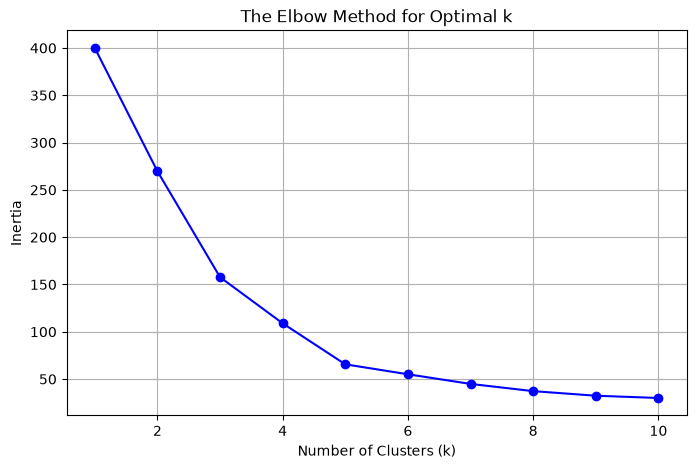

In [74]:
import matplotlib.pyplot as plt

# 2. Create a figure
plt.figure(figsize=(8, 5))

# 3 & 4. Plot range(1, 11) against inertias with circular markers
plt.plot(range(1, 11), inertias, marker='o', linestyle='-', color='b')

# 5. Add a title and axis labels
plt.title('The Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.grid(True)

# 6. Display the plot
plt.show()

In [75]:
from sklearn.metrics import silhouette_score

# 2 & 3. Calculate silhouette score and store in sil_score
sil_score = silhouette_score(X_scaled, kmeans.labels_)

# 4. Print the score rounded to three decimal places
print(f"Silhouette Score: {sil_score:.3f}")

Silhouette Score: 0.555


In [76]:
from sklearn.metrics import silhouette_score

# 1. Create an empty list named silhouette_scores
silhouette_scores = []

# 2. Loop through K values from 2 to 10
for k in range(2, 11):
    # 3. Create and fit a new K-Means model
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    
    # 4. Calculate its silhouette score using model labels
    score = silhouette_score(X_scaled, model.labels_)
    
    # 5. Append each score to the list
    silhouette_scores.append(score)

# 6. Print the scores (rounded for clean readability)
print("Silhouette scores:", [round(s, 3) for s in silhouette_scores])

Silhouette scores: [0.321, 0.467, 0.494, 0.555, 0.54, 0.528, 0.455, 0.457, 0.443]


## I evaluated K-Means clustering using the Elbow Method and Silhouette Score. The inertia curve showed diminishing improvements after five clusters, and K = 5 achieved the highest silhouette score of 0.555 among the tested values. Therefore, I selected five clusters for further analysis.

In [77]:
import numpy as np

# 1 & 2. Convert scaled cluster centers back to original units using scaler
centers_original = scaler.inverse_transform(kmeans.cluster_centers_)

# 3. Print the shape of centers_original
print("Shape of centers_original:", centers_original.shape)

# 4. Print original-scale centroid coordinates rounded to two decimal places
print("\nCentroid coordinates (original scale):\n", np.round(centers_original, 2))

Shape of centers_original: (5, 2)

Centroid coordinates (original scale):
 [[55.3  49.52]
 [86.54 82.13]
 [25.73 79.36]
 [88.2  17.11]
 [26.3  20.91]]


In [78]:
# 1. Create a copy of df named df_segmented
df_segmented = df.copy()

# 2. Add a new column named Cluster containing kmeans.labels_
df_segmented['Cluster'] = kmeans.labels_

# 3. Display the first five rows
display(df_segmented.head())

# 4. Print the number of customers in each cluster using value_counts()
print("\nCustomer count per cluster:")
print(df_segmented['Cluster'].value_counts().sort_index())

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4



Customer count per cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


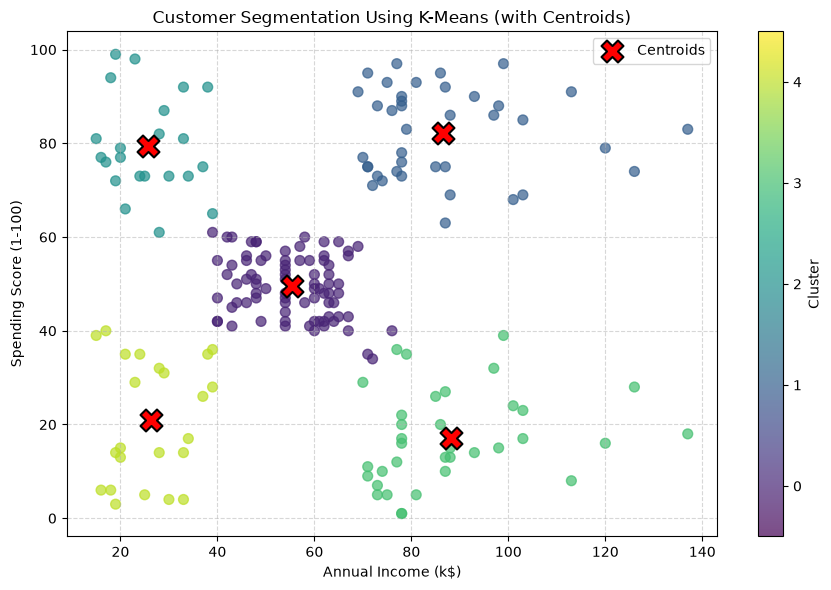

In [79]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

# 1. Plot customer data points
scatter = plt.scatter(
    df_segmented['Annual Income (k$)'],
    df_segmented['Spending Score (1-100)'],
    c=df_segmented['Cluster'],
    cmap='viridis',
    vmin=-0.5,
    vmax=kmeans.n_clusters - 0.5,
    s=50,
    alpha=0.7
)

# 2. Plot cluster centroids in original scale
plt.scatter(
    centers_original[:, 0],
    centers_original[:, 1],
    marker='X',
    s=250,
    color='red',
    edgecolors='black',
    linewidths=1.5,
    label='Centroids',
    zorder=5
)

# 3. Add labels and title
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Customer Segmentation Using K-Means (with Centroids)')

# 4. Colorbar showing all 5 cluster IDs
cbar = plt.colorbar(scatter, ticks=range(kmeans.n_clusters))
cbar.set_label('Cluster')

# 5. Final formatting
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

## Business Insights & Customer Segmentation Summary

The K-Means model successfully segmented the 200 mall customers into five distinct groups based on their **Annual Income** and **Spending Score**.

### Cluster Breakdown

| Cluster | Customer Segment | Customers | Percentage |
| :---: | :--- | :---: | :---: |
| **0** | Average Income, Average Spending | 81 | 40.5% |
| **1** | High Income, High Spending | 39 | 19.5% |
| **2** | Low Income, High Spending | 22 | 11.0% |
| **3** | High Income, Low Spending | 35 | 17.5% |
| **4** | Low Income, Low Spending | 23 | 11.5% |

### Key Findings

* **Largest Segment:** Average-income, average-spending customers form the largest group, representing **40.5%** of the dataset.
* **High-Value Targets:** High-income, high-spending customers represent an ideal target for premium offers, VIP tiers, and loyalty programs.
* **Growth Opportunity:** High-income, low-spending customers present a strategic engagement opportunity to understand why they spend less despite higher earning potential.
* **Targeted Promotions:** The remaining segments can be addressed with tailored, relevant promotional campaigns.

### Conclusion

K-Means clustering identified five interpretable customer segments. The optimal number of clusters was selected using the Elbow Method and Silhouette Score, with **$K = 5$** achieving a silhouette score of approximately **0.555**. 

These findings provide a solid, data-driven starting point for customer-focused marketing strategies, though recommendations should be further validated using additional behavioral data.

In [80]:
import joblib

joblib.dump(kmeans, '../models/kmeans_model.pkl')
joblib.dump(scaler, '../models/scaler.pkl')

print("Model and scaler saved successfully!")

Model and scaler saved successfully!
